# Scenes

Several animations in one file. Each ``svg.Scene`` subclass is one clip: ``Title`` plays SMIL presets,
``Bars`` grows a chart from ``update(seconds)``. ``svgwriter animate`` renders every scene in the file to
``<ClassName>.mp4``, or only the ones named.

    python -m svgwriter animate examples/13_scenes.py --list
    python -m svgwriter animate examples/13_scenes.py Bars --format gif
    python 13_scenes.py                                writes each scene as SVG and PNG

In [1]:
import svgwriter as svg

A base class shares the canvas and colors. Its name starts with `_`, so `svgwriter animate` does not
treat it as a scene of its own.

In [2]:
INK = "#1f2937"
PAPER = "#f8fafc"
ACCENT = "#0ea5e9"


class _Card(svg.Scene):
    width, height = 320, 180
    fps = 24

    def build(self, doc: svg.Document) -> None:
        doc.rect(0, 0, self.width, self.height, fill=PAPER)

`Title` animates with SMIL only: the presets add `<animate>` elements, the scene's length comes from
them, and the notebook shows the animated SVG.

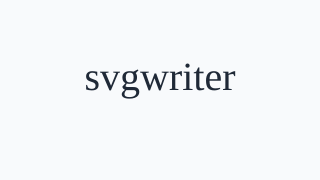

In [3]:
class Title(_Card):
    def build(self, doc: svg.Document) -> None:
        super().build(doc)
        title = doc.text("svgwriter", x=self.width / 2, y=90, font_size=40, fill=INK, text_anchor="middle")
        title.animate.fade_in(1)
        rule = doc.line(60, 110, 260, 110, stroke=ACCENT, stroke_width=4)
        rule.animate.draw(1.5)


Title()

`Bars` moves from Python: `update` sets each bar's height for the time it is given, so any frame can
be drawn directly.

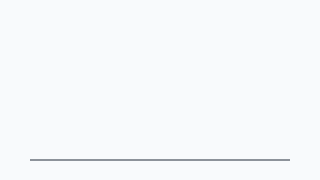

In [4]:
VALUES = (0.4, 0.9, 0.6, 0.75)
BAR = 40
GAP = 25
BASELINE = 160
TALLEST = 140


class Bars(_Card):
    duration = 1.5

    def build(self, doc: svg.Document) -> None:
        super().build(doc)
        doc.line(30, BASELINE, 290, BASELINE, stroke=INK)
        self.bars = [doc.rect(50 + i * (BAR + GAP), BASELINE, BAR, 0, fill=ACCENT) for i in range(len(VALUES))]

    def update(self, seconds: float) -> None:
        progress = min(seconds / self.duration, 1.0)
        for bar, value in zip(self.bars, VALUES, strict=True):
            height = value * TALLEST * progress
            bar.y = BASELINE - height
            bar.height = height


bars = Bars()
bars.update(Bars.duration)
bars

`render(seconds)` draws one frame as PNG and `save` encodes the whole scene with ffmpeg
(`.mp4`, `.gif`, `.webm`, or numbered `.png` frames). Here each scene is saved as SVG and as a still.

In [5]:
if __name__ == "__main__":
    for scene in (Title(), bars):
        scene.document.save(f"13_{scene.name}.svg")
        with open(f"13_{scene.name}.png", "wb") as still:
            still.write(scene.render(1.0))